# SC4002 — Joint Text CNN, Stage 1 (Teaching / Experimental Implementation)


## 0. Imports, configuration, and robust dataset path
This replaces the original `main.ipynb` import cell with only the required packages. The parser/evaluator code below is copied from your group's shared `main.ipynb`.

In [1]:
import os
import re
import csv
import json
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
BATCH_SIZE = 64
EMBED_DIM = 128
CNN_CHANNELS = 128
CNN_KERNELS = (3, 5)
DROPOUT = 0.25
MAX_EPOCHS = 80
EARLY_STOP_PATIENCE = 12
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
SLOT_REGEX = re.compile(r"\[([^\[\]:]+)\s*:\s*([^\[\]]+)\]")

# Supports VS Code with the working directory set to either project root or Source/.
possible_paths = [
    Path.cwd() / "Data/data/en-US.jsonl",
    Path.cwd().parent / "Data/data/en-US.jsonl",
    Path.cwd() / "SC4002-Group-Project-main/Data/data/en-US.jsonl",
]
DATA_PATH = next((p.resolve() for p in possible_paths if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Cannot find MASSIVE en-US.jsonl. Put this notebook in the group's Source/ "
        "directory, keep Data/data/en-US.jsonl, and run from Source/ or project root. "
        f"Working directory: {Path.cwd()}"
    )

PROJECT_ROOT = DATA_PATH.parent.parent.parent
SAVE_DIR = PROJECT_ROOT / "Results_CNN_80"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = SAVE_DIR / "cnn_stage1_best.pt"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
'''
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")'''
DEVICE = torch.device("cpu")

print("Dataset:", DATA_PATH)
print("Output directory:", SAVE_DIR)
print("Device:", DEVICE)

Dataset: /Users/shiqing/Desktop/NTU/SC4002/SC4002-Group-Project/Data/data/en-US.jsonl
Output directory: /Users/shiqing/Desktop/NTU/SC4002/SC4002-Group-Project/Results_CNN_80
Device: cpu


## 1. Shared `main.ipynb`: parse MASSIVE JSONL, official splits
Below we reuse your group's existing code (without modifying the original notebook).

In [2]:
def parse_slots(annot_utt):
    # get list of (slot_type, slot_span) from annot_utt
    # turns the [color_type : pink] into ("color_type", "pink")
    return [(t.strip(), s.strip()) for t, s in SLOT_REGEX.findall(annot_utt)]

def load_massive(path=DATA_PATH):
    splits = {"train": [], "dev": [], "test": []}
    with open(path, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            r = json.loads(line)
            splits[r["partition"]].append({
                "id": r["id"],
                "scenario": r["scenario"],
                "intent": r["intent"],
                "utt": r["utt"],
                "annot_utt": r["annot_utt"],
                "slots": parse_slots(r["annot_utt"]),  
            })
    return splits

In [3]:
splits = load_massive()
expected = {"train": 11514, "dev": 2033, "test": 2974}
for k, n in expected.items():
    print(f"{k}: {len(splits[k])}")
    assert len(splits[k]) == n
assert sum(len(v) for v in splits.values()) == 16521

intents = sorted({r["intent"] for r in splits["train"]})
slotTypes = sorted({t for r in splits["train"] for t, _ in r["slots"]})
print("intents:", len(intents), "| slot types:", len(slotTypes))
print(splits["train"][1])

train: 11514
dev: 2033
test: 2974
intents: 60 | slot types: 55
{'id': '2', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'set an alarm for two hours from now', 'annot_utt': 'set an alarm for [time : two hours from now]', 'slots': [('time', 'two hours from now')]}


## 2. Shared `main.ipynb`: BIOES tags and exact-span decoding
Each word gets one BIOES label. The same decoding rule will be used for dev and test scoring.

In [4]:
def annot_to_bioes(annot_utt):
    """Convert annotated text into tokens and BIOES tags."""
    # use whitespace to split, so just do utt.split()
    # then assign tags based on the slots
    # theres 55 slot types, so they will be tagged as B-time, I-time, B-house_place that kind
    # the 55 types are defined in the above cell

    tokens = []
    tags = []
    position = 0

    # Process each annotated slot, such as [time : five am]
    for match in SLOT_REGEX.finditer(annot_utt):

        # Words outside a slot are tagged as O
        outsideText = annot_utt[position:match.start()]

        for word in outsideText.split():
            tokens.append(word)
            tags.append("O")

        slotType = match.group(1).strip()
        words = match.group(2).split()

        # Assign BIOES tag for each word 
        for i, word in enumerate(words):
            if len(words) == 1:
                tag = f"S-{slotType}"
            elif i == 0:
                tag = f"B-{slotType}"
            elif i == len(words) - 1:
                tag = f"E-{slotType}"
            else:
                tag = f"I-{slotType}"

            tokens.append(word)
            tags.append(tag)

        position = match.end()

    # Process any remaining words after the last slot
    for word in annot_utt[position:].split():
        tokens.append(word)
        tags.append("O")

    return tokens, tags


def build_tag_vocab(records):

    slotTypes = sorted({
        slotType
        for record in records
        for slotType, _ in record["slots"]
    })

    tags = ["O"]

    for slotType in slotTypes:
        for prefix in ("B", "I", "E", "S"):
            tags.append(f"{prefix}-{slotType}")

    tagToId = {tag: i for i, tag in enumerate(tags)}

    return tags, tagToId

In [5]:
def decode_bioes(tokens, tags):
    """Convert BIOES tags into a list of (slotType, slotSpan) pairs."""

    spans = []
    currentType = None
    currentTokens = []

    def closeSpan():
        nonlocal currentType, currentTokens

        if currentType is not None:
            slotText = " ".join(currentTokens)
            spans.append((currentType, slotText))

        currentType = None
        currentTokens = []

    for token, tag in zip(tokens, tags):

        if tag == "O":
            closeSpan()
            continue

        prefix, slotType = tag.split("-", 1)

        if prefix == "B":
            closeSpan()
            currentType = slotType
            currentTokens = [token]

        elif prefix == "I":
            if currentType == slotType:
                currentTokens.append(token)
            else:
                closeSpan()
                currentType = slotType
                currentTokens = [token]

        elif prefix == "E":
            if currentType == slotType:
                currentTokens.append(token)
                closeSpan()
            else:
                closeSpan()
                spans.append((slotType, token))

        elif prefix == "S":
            closeSpan()
            spans.append((slotType, token))

        else:
            closeSpan()

    # Include any unfinished span at the end
    closeSpan()

    return spans

## 3. Shared `main.ipynb`: metrics
`eval_macro_f1` is the group's existing function name, but its implementation is actually **slot micro-F1 over exact (slot type, slot text) pairs**, as required by the assignment. We preserve the group's scoring function for comparability.

In [6]:
def eval_intent_accuracy(actual, predicted):
    """Calculate the percentage of correctly predicted intents."""

    assert len(actual) == len(predicted)

    correctCount = sum(
        gold == pred
        for gold, pred in zip(actual, predicted)
    )

    return 100.0 * correctCount / len(actual)

def eval_macro_f1(actual, predicted):
    """Calculate micro F1 for slot types and spans across all utterances."""

    assert len(actual) == len(predicted)

    truePositives = 0
    falsePositives = 0
    falseNegatives = 0

    for act, pred in zip(actual, predicted):
        actualCount = Counter(act)
        predCount= Counter(pred)

        matchedCount = sum((actualCount & predCount).values())

        truePositives += matchedCount
        falsePositives += sum(predCount.values()) - matchedCount
        falseNegatives += sum(actualCount.values()) - matchedCount

    denominator = (
        2 * truePositives
        + falsePositives
        + falseNegatives
    )

    if denominator == 0:
        return 0.0

    return 100.0 * 2 * truePositives / denominator

def evaluate(goldIntents, predIntents, goldSlots, predSlots):
    """Calculate and return intent accuracy and slot F1."""

    intentAcc = round(eval_intent_accuracy(goldIntents, predIntents), 2)

    slotF1 = round(eval_macro_f1(goldSlots, predSlots), 2)

    return {
        "intent_acc": intentAcc,
        "slot_f1": slotF1,
    }

## 4. Train-only vocabulary and label mapping
Important: fit the word vocabulary, slot labels, and intent labels using **training examples only**; dev/test are not used to build these mappings.

In [7]:
word_counts = Counter()
for record in splits["train"]:
    tokens, _ = annot_to_bioes(record["annot_utt"])
    word_counts.update(token.lower() for token in tokens)

# Fixed ordering makes the numeric word IDs reproducible.
id_to_word = [PAD_TOKEN, UNK_TOKEN] + sorted(word_counts)
word_to_id = {word: index for index, word in enumerate(id_to_word)}
PAD_ID = word_to_id[PAD_TOKEN]
UNK_ID = word_to_id[UNK_TOKEN]

id_to_tag, tag_to_id = build_tag_vocab(splits["train"])
id_to_intent = sorted({r["intent"] for r in splits["train"]})
intent_to_id = {label: i for i, label in enumerate(id_to_intent)}

assert len(id_to_intent) == 60
assert len(id_to_tag) == 221
for split_name in ("train", "dev"):
    for record in splits[split_name]:
        tokens, tags = annot_to_bioes(record["annot_utt"])
        assert tokens == record["utt"].split(), f"Token alignment failed: {record['id']}"
        assert all(tag in tag_to_id for tag in tags)
        assert record["intent"] in intent_to_id

print(f"Vocab size: {len(id_to_word)}")
print(f"Slot BIOES labels: {len(id_to_tag)}")
print(f"Intent classes: {len(id_to_intent)}")
print("Sample tokens:", annot_to_bioes(splits["train"][0]["annot_utt"])[0])

Vocab size: 5304
Slot BIOES labels: 221
Intent classes: 60
Sample tokens: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']


## 5. Dataset and batches
Every item returns token IDs, BIOES tag IDs, intent ID, and original gold labels. Only within-batch padding is applied (`0` for tokens; `-100` for ignored slot labels).

In [8]:
class MassiveJointDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        tokens, tags = annot_to_bioes(record["annot_utt"])
        assert tokens == record["utt"].split()
        return {
            "token_ids": torch.tensor(
                [word_to_id.get(w.lower(), UNK_ID) for w in tokens], dtype=torch.long
            ),
            "tag_ids": torch.tensor([tag_to_id[t] for t in tags], dtype=torch.long),
            "intent_id": intent_to_id[record["intent"]],
            "tokens": tokens,
            "gold_intent": record["intent"],
            "gold_slots": record["slots"],
        }


def collate_joint(items):
    return {
        "token_ids": pad_sequence(
            [x["token_ids"] for x in items],
            batch_first=True, padding_value=PAD_ID
        ),
        "tag_ids": pad_sequence(
            [x["tag_ids"] for x in items],
            batch_first=True, padding_value=-100
        ),
        "intent_ids": torch.tensor([x["intent_id"] for x in items], dtype=torch.long),
        "tokens": [x["tokens"] for x in items],
        "gold_intents": [x["gold_intent"] for x in items],
        "gold_slots": [x["gold_slots"] for x in items],
    }

train_loader = DataLoader(
    MassiveJointDataset(splits["train"]),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_joint, num_workers=0
)
dev_loader = DataLoader(
    MassiveJointDataset(splits["dev"]),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_joint, num_workers=0
)

sample = next(iter(train_loader))
print("Input token shape:", tuple(sample["token_ids"].shape))
print("BIOES label shape:", tuple(sample["tag_ids"].shape))
print("Intent label shape:", tuple(sample["intent_ids"].shape))

Input token shape: (64, 15)
BIOES label shape: (64, 15)
Intent label shape: (64,)


## 6. Joint 1D CNN encoder with two task heads

- Word embedding: learned from scratch; no pretrained language model.
- Parallel 1D convolutions of kernel sizes 3 and 5, with a residual convolution for additional context.
- **Token-level** slot head: `[batch, sequence_length, 221]` logits.
- **Sentence-level** intent head: `[batch, 60]` logits from masked max and mean pooling.
- Padding positions are excluded from pooling; ignored in the slot loss.

In [9]:
class JointTextCNN(nn.Module):
    def __init__(self, vocab_size, num_tags, num_intents,
                 embedding_dim=EMBED_DIM, channels=CNN_CHANNELS,
                 kernels=CNN_KERNELS, dropout=DROPOUT, pad_id=PAD_ID):
        super().__init__()
        self.pad_id = pad_id
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_id)
        self.embedding_dropout = nn.Dropout(dropout)

        self.convs = nn.ModuleList([
            nn.Conv1d(embedding_dim, channels, kernel_size=k, padding=k // 2)
            for k in kernels
        ])
        feature_dim = channels * len(kernels)
        self.layer_norm = nn.LayerNorm(feature_dim)
        self.refine = nn.Conv1d(feature_dim, feature_dim, kernel_size=3, padding=1)
        self.feature_dropout = nn.Dropout(dropout)

        self.slot_head = nn.Linear(feature_dim, num_tags)
        self.intent_head = nn.Sequential(
            nn.Linear(feature_dim * 2, feature_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(feature_dim, num_intents),
        )

    def forward(self, token_ids):
        # token_ids: [batch, length]
        mask = token_ids.ne(self.pad_id)  # True on actual words
        embedded = self.embedding_dropout(self.embedding(token_ids))
        channels_first = embedded.transpose(1, 2)  # [batch, embed_dim, length]

        parallel = torch.cat(
            [F.relu(conv(channels_first)) for conv in self.convs], dim=1
        )
        features = self.layer_norm(parallel.transpose(1, 2))
        refined = F.relu(self.refine(features.transpose(1, 2))).transpose(1, 2)
        features = self.feature_dropout(features + refined)

        slot_logits = self.slot_head(features)  # [batch, length, num_tags]

        valid = mask.unsqueeze(-1)
        mean_pooled = (features * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1)
        max_pooled = features.masked_fill(~valid, -1e4).max(dim=1).values
        pooled = torch.cat([mean_pooled, max_pooled], dim=-1)
        intent_logits = self.intent_head(pooled)  # [batch, num_intents]
        return intent_logits, slot_logits

model = JointTextCNN(len(id_to_word), len(id_to_tag), len(id_to_intent)).to(DEVICE)
total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert total_parameters <= 20_000_000, "Exceeded 20M-parameter cap"

print("Model:", model)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
model.eval()
with torch.no_grad():
    sample_intent, sample_slots = model(sample["token_ids"].to(DEVICE))
print("Intent logits:", tuple(sample_intent.shape))
print("Slot logits:", tuple(sample_slots.shape))
assert sample_intent.shape == (sample["token_ids"].size(0), 60)
assert sample_slots.shape[:2] == sample["token_ids"].shape
assert sample_slots.shape[-1] == 221

Model: JointTextCNN(
  (embedding): Embedding(5304, 128, padding_idx=0)
  (embedding_dropout): Dropout(p=0.25, inplace=False)
  (convs): ModuleList(
    (0): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  )
  (layer_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (refine): Conv1d(256, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (feature_dropout): Dropout(p=0.25, inplace=False)
  (slot_head): Linear(in_features=256, out_features=221, bias=True)
  (intent_head): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Linear(in_features=256, out_features=60, bias=True)
  )
)
Total parameters: 1,211,161
Trainable parameters: 1,211,161
Intent logits: (64, 60)
Slot logits: (64, 15, 221)


## 7. Loss, one-epoch training and validation
The joint loss is `intent_cross_entropy + slot_cross_entropy`; padding slot positions use target `-100` and do not contribute. Model selection score is the arithmetic mean of **dev Intent Accuracy** and **dev Slot Micro F1**. The test split is never used here.

In [10]:
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)


def calculate_losses(intent_logits, slot_logits, intent_ids, tag_ids):
    intent_loss = F.cross_entropy(intent_logits, intent_ids)
    slot_loss = F.cross_entropy(
        slot_logits.reshape(-1, slot_logits.shape[-1]),
        tag_ids.reshape(-1),
        ignore_index=-100,
    )
    return intent_loss, slot_loss, intent_loss + slot_loss


def train_one_epoch(model, loader, optimizer):
    model.train()
    seen = 0
    loss_sum = 0.0
    intent_sum = 0.0
    slot_sum = 0.0

    for batch in loader:
        token_ids = batch["token_ids"].to(DEVICE)
        intent_ids = batch["intent_ids"].to(DEVICE)
        tag_ids = batch["tag_ids"].to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        intent_logits, slot_logits = model(token_ids)
        intent_loss, slot_loss, loss = calculate_losses(
            intent_logits, slot_logits, intent_ids, tag_ids
        )
        loss.backward()
        clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        n = token_ids.size(0)
        seen += n
        loss_sum += loss.item() * n
        intent_sum += intent_loss.item() * n
        slot_sum += slot_loss.item() * n

    return {
        "train_loss": loss_sum / seen,
        "train_intent_loss": intent_sum / seen,
        "train_slot_loss": slot_sum / seen,
    }


@torch.no_grad()
def evaluate_loader(model, loader, collect_examples=False):
    model.eval()
    seen = 0
    loss_sum = 0.0
    gold_intents, pred_intents = [], []
    gold_slots, pred_slots = [], []
    examples = []

    for batch in loader:
        token_ids = batch["token_ids"].to(DEVICE)
        intent_ids = batch["intent_ids"].to(DEVICE)
        tag_ids = batch["tag_ids"].to(DEVICE)
        intent_logits, slot_logits = model(token_ids)
        _, _, loss = calculate_losses(intent_logits, slot_logits, intent_ids, tag_ids)

        n = token_ids.size(0)
        seen += n
        loss_sum += loss.item() * n
        intent_pred_ids = intent_logits.argmax(dim=-1).cpu().tolist()
        slot_pred_ids = slot_logits.argmax(dim=-1).cpu().tolist()

        for i, tokens in enumerate(batch["tokens"]):
            pred_intent = id_to_intent[intent_pred_ids[i]]
            pred_tags = [id_to_tag[j] for j in slot_pred_ids[i][:len(tokens)]]
            pred_slot = decode_bioes(tokens, pred_tags)
            gold_intent = batch["gold_intents"][i]
            gold_slot = batch["gold_slots"][i]

            gold_intents.append(gold_intent)
            pred_intents.append(pred_intent)
            gold_slots.append(gold_slot)
            pred_slots.append(pred_slot)

            if collect_examples:
                examples.append({
                    "utterance": " ".join(tokens),
                    "gold_intent": gold_intent,
                    "pred_intent": pred_intent,
                    "gold_slots": gold_slot,
                    "pred_slots": pred_slot,
                })

    metrics = evaluate(gold_intents, pred_intents, gold_slots, pred_slots)
    result = {"loss": loss_sum / seen, **metrics}
    if collect_examples:
        result["examples"] = examples
    return result


def dev_selection_score(metrics):
    return (metrics["intent_acc"] + metrics["slot_f1"]) / 2.0

print("Training and evaluation helpers ready")

Training and evaluation helpers ready


## 8. Full training: best dev checkpoint and early stopping
All per-epoch train/dev losses, dev intent accuracy, slot micro F1, selection score, and elapsed time are stored. The best model is selected from **dev only**.

In [11]:
history = []
best_dev_score = float("-inf")
best_epoch = None
best_dev_metrics = None
stale_epochs = 0
training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_result = train_one_epoch(model, train_loader, optimizer)
    dev_result = evaluate_loader(model, dev_loader)
    score = dev_selection_score(dev_result)
    elapsed = time.perf_counter() - epoch_start

    row = {
        "epoch": epoch,
        **train_result,
        "dev_loss": dev_result["loss"],
        "dev_intent_acc": dev_result["intent_acc"],
        "dev_slot_micro_f1": dev_result["slot_f1"],
        "dev_selection_score": score,
        "epoch_seconds": elapsed,
    }
    history.append(row)

    if score > best_dev_score:
        best_dev_score = score
        best_epoch = epoch
        best_dev_metrics = dict(dev_result)
        stale_epochs = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "best_epoch": best_epoch,
            "best_dev_score": best_dev_score,
            "best_dev_metrics": best_dev_metrics,
            "model_config": {
                "vocab_size": len(id_to_word),
                "num_tags": len(id_to_tag),
                "num_intents": len(id_to_intent),
                "embedding_dim": EMBED_DIM,
                "channels": CNN_CHANNELS,
                "kernels": tuple(CNN_KERNELS),
                "dropout": DROPOUT,
                "pad_id": PAD_ID,
            },
            "id_to_word": id_to_word,
            "id_to_tag": id_to_tag,
            "id_to_intent": id_to_intent,
            "seed": SEED,
        }, CHECKPOINT_PATH)
        improved = " *saved*"
    else:
        stale_epochs += 1
        improved = ""

    print(
        f"Epoch {epoch:02d} | train loss={row['train_loss']:.4f} | "
        f"dev loss={row['dev_loss']:.4f} | "
        f"dev intent={row['dev_intent_acc']:.2f}% | "
        f"dev slot micro-F1={row['dev_slot_micro_f1']:.2f}% | "
        f"dev mean={score:.2f}% | {elapsed:.1f}s{improved}",
        flush=True,
    )

    if stale_epochs >= EARLY_STOP_PATIENCE:
        print(f"Early stopping after {EARLY_STOP_PATIENCE} epochs without improvement")
        break

training_seconds = time.perf_counter() - training_start
print("\nBest epoch:", best_epoch)
print(f"Best dev selection score: {best_dev_score:.2f}%")
print("Checkpoint:", CHECKPOINT_PATH)
print(f"Total training time: {training_seconds:.1f} seconds")

Epoch 01 | train loss=4.0126 | dev loss=2.3303 | dev intent=60.80% | dev slot micro-F1=48.05% | dev mean=54.42% | 12.1s *saved*
Epoch 02 | train loss=2.1986 | dev loss=1.6469 | dev intent=73.73% | dev slot micro-F1=57.58% | dev mean=65.66% | 11.9s *saved*
Epoch 03 | train loss=1.6796 | dev loss=1.5093 | dev intent=75.70% | dev slot micro-F1=60.27% | dev mean=67.98% | 12.0s *saved*
Epoch 04 | train loss=1.4154 | dev loss=1.3619 | dev intent=78.60% | dev slot micro-F1=60.28% | dev mean=69.44% | 12.4s *saved*
Epoch 05 | train loss=1.2020 | dev loss=1.3282 | dev intent=79.49% | dev slot micro-F1=63.07% | dev mean=71.28% | 11.6s *saved*
Epoch 06 | train loss=1.0773 | dev loss=1.2999 | dev intent=79.59% | dev slot micro-F1=63.23% | dev mean=71.41% | 11.4s *saved*
Epoch 07 | train loss=0.9605 | dev loss=1.2802 | dev intent=80.18% | dev slot micro-F1=63.48% | dev mean=71.83% | 11.6s *saved*
Epoch 08 | train loss=0.8638 | dev loss=1.2920 | dev intent=80.37% | dev slot micro-F1=64.04% | dev mean

## 9. Export the actual training logs and plot learning curves
No scores are manually entered. `training_log.csv` and `cnn_stage1_learning_curves.png` are generated directly from executed logs.

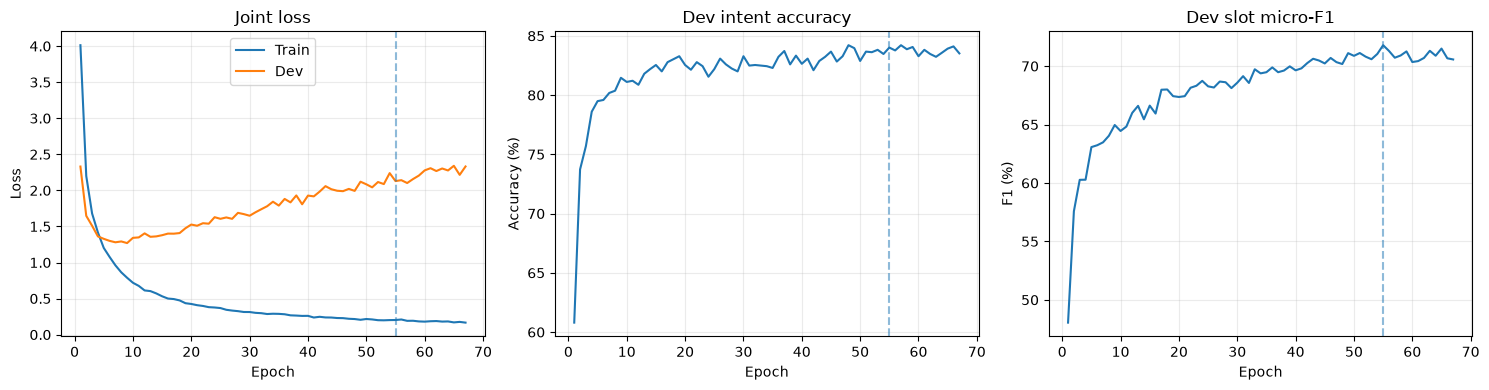

Training log: /Users/shiqing/Desktop/NTU/SC4002/SC4002-Group-Project/Results_CNN_80/cnn_stage1_training_log.csv
Learning curves: /Users/shiqing/Desktop/NTU/SC4002/SC4002-Group-Project/Results_CNN_80/cnn_stage1_learning_curves.png


In [12]:
log_path = SAVE_DIR / "cnn_stage1_training_log.csv"
with open(log_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
    writer.writeheader()
    writer.writerows(history)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
epochs = [row["epoch"] for row in history]
axes[0].plot(epochs, [row["train_loss"] for row in history], label="Train")
axes[0].plot(epochs, [row["dev_loss"] for row in history], label="Dev")
axes[0].set(title="Joint loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(epochs, [row["dev_intent_acc"] for row in history])
axes[1].set(title="Dev intent accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
axes[2].plot(epochs, [row["dev_slot_micro_f1"] for row in history])
axes[2].set(title="Dev slot micro-F1", xlabel="Epoch", ylabel="F1 (%)")
for ax in axes:
    ax.axvline(best_epoch, linestyle="--", alpha=0.5, label="Selected epoch")
    ax.grid(alpha=0.25)
fig.tight_layout()
figure_path = SAVE_DIR / "cnn_stage1_learning_curves.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("Training log:", log_path)
print("Learning curves:", figure_path)

## 10. Reload the frozen best checkpoint, re-evaluate dev, then evaluate test **once**
This happens after model selection. We **do not** update model weights after reading the test results. The reloaded dev metrics should match the saved best epoch's metrics.

In [13]:
# The file was just produced by this notebook, so its contents are trusted.
try:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
except TypeError:  # Older PyTorch versions
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)

frozen_model = JointTextCNN(**checkpoint["model_config"]).to(DEVICE)
frozen_model.load_state_dict(checkpoint["model_state_dict"])
frozen_model.eval()

reloaded_dev = evaluate_loader(frozen_model, dev_loader)
assert reloaded_dev["intent_acc"] == checkpoint["best_dev_metrics"]["intent_acc"]
assert reloaded_dev["slot_f1"] == checkpoint["best_dev_metrics"]["slot_f1"]
print("Reloaded best epoch:", checkpoint["best_epoch"])
print("Reloaded dev: intent accuracy={:.2f}%, slot micro-F1={:.2f}%".format(
    reloaded_dev["intent_acc"], reloaded_dev["slot_f1"]
))

# Official held-out test: run after selecting and freezing the checkpoint.
test_loader = DataLoader(
    MassiveJointDataset(splits["test"]), batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_joint, num_workers=0
)
test_result = evaluate_loader(frozen_model, test_loader, collect_examples=True)
print("Frozen test: intent accuracy={:.2f}%, slot micro-F1={:.2f}%".format(
    test_result["intent_acc"], test_result["slot_f1"]
))

Reloaded best epoch: 55
Reloaded dev: intent accuracy=84.01%, slot micro-F1=71.79%
Frozen test: intent accuracy=82.78%, slot micro-F1=69.27%


## 11. Save numeric summary and a few reproducible errors
For the group report and AI-collaboration Stage 2 later: report dev/test metrics as percentages with two decimals; include parameter count and best epoch. **Do not tune Stage 1 using these test errors.**

In [14]:
summary = {
    "model": "Joint Text CNN (from scratch)",
    "parameters_total": total_parameters,
    "parameters_trainable": trainable_parameters,
    "best_epoch": best_epoch,
    "epochs_run": len(history),
    "training_seconds": round(training_seconds, 2),
    "dev_intent_accuracy_pct": reloaded_dev["intent_acc"],
    "dev_slot_micro_f1_pct": reloaded_dev["slot_f1"],
    "test_intent_accuracy_pct": test_result["intent_acc"],
    "test_slot_micro_f1_pct": test_result["slot_f1"],
    "checkpoint": CHECKPOINT_PATH.name,
    "selection_rule": "best dev mean of intent accuracy (%) and exact slot micro F1 (%)",
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
}
summary_path = SAVE_DIR / "cnn_stage1_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

errors = [
    item for item in test_result["examples"]
    if item["gold_intent"] != item["pred_intent"]
    or Counter(item["gold_slots"]) != Counter(item["pred_slots"])
]
print("\nSTAGE 1 FINAL RESULTS")
print(json.dumps(summary, indent=2, ensure_ascii=False))
print(f"\nTest examples with at least one error: {len(errors)} / {len(test_result['examples'])}")
for item in errors[:5]:
    print("\nUtterance:", item["utterance"])
    print("Intent: gold=", item["gold_intent"], "pred=", item["pred_intent"])
    print("Slots: gold=", item["gold_slots"])
    print("       pred=", item["pred_slots"])
print("\nSaved summary:", summary_path)
print("All files saved in:", SAVE_DIR)


STAGE 1 FINAL RESULTS
{
  "model": "Joint Text CNN (from scratch)",
  "parameters_total": 1211161,
  "parameters_trainable": 1211161,
  "best_epoch": 55,
  "epochs_run": 67,
  "training_seconds": 783.53,
  "dev_intent_accuracy_pct": 84.01,
  "dev_slot_micro_f1_pct": 71.79,
  "test_intent_accuracy_pct": 82.78,
  "test_slot_micro_f1_pct": 69.27,
  "checkpoint": "cnn_stage1_best.pt",
  "selection_rule": "best dev mean of intent accuracy (%) and exact slot micro F1 (%)",
  "learning_rate": 0.001,
  "batch_size": 64,
  "seed": 42
}

Test examples with at least one error: 1241 / 2974

Utterance: pink is all we need
Intent: gold= iot_hue_lightchange pred= qa_factoid
Slots: gold= [('color_type', 'pink')]
       pred= []

Utterance: and the darkness has fallen
Intent: gold= iot_hue_lighton pred= general_quirky
Slots: gold= []
       pred= []

Utterance: it's dirty here make some noise
Intent: gold= iot_cleaning pred= play_music
Slots: gold= []
       pred= []

Utterance: hoover the hallway
Int